# 03 · Spectral features per epoch

For every sample × epoch × channel: the power spectrum from clean 4-s segments, log band power
(delta, theta, alpha, sigma, beta), and the aperiodic exponent and offset from specparam
(Donoghue et al. 2020), fitted 1-30 Hz. The posterior average (O1, O2, Oz, P3, P4, Pz) follows the
pre-awakening "hot zone" of Siclari et al. (2017).

Output: `derived/features_long.csv`, `derived/features_roi.csv`, `derived/spectra.npz`.
Runtime: CPU, a few minutes. No statistics here: tests come in NB4.

In [1]:
# Bootstrap: same cell in every notebook. On Colab: mount Drive, get the repo, install extras.
# The repo is private: add a read-only GitHub token to Colab Secrets as GH_TOKEN.
import os, sys, subprocess, base64
REPO_URL = "https://github.com/sanjanasinghx/dream2image-es606.git"
if "google.colab" in sys.modules and not os.environ.get("D2I_HEADLESS"):  # headless = run by d2i.runner
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    REPO = "/content/dream2image-es606"
    try:
        auth = base64.b64encode(f"x-access-token:{userdata.get('GH_TOKEN')}".encode()).decode()
        git = ["git", "-c", f"http.extraHeader=Authorization: Basic {auth}"]  # token never written to disk
    except Exception:
        git = ["git"]  # no secret: works once the repo is public
    if not os.path.exists(REPO):
        subprocess.run([*git, "clone", "-q", REPO_URL, REPO], check=True)
    else:
        subprocess.run([*git, "-C", REPO, "pull", "-q"], check=True)
    freeze = lambda: subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
    before = freeze()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{REPO}/requirements-colab.txt"], check=True)
    if freeze() != before:  # e.g. numpy upgraded under an already-loaded copy -> broken imports
        print("Packages changed: restarting the runtime. When it reconnects, Run all again.")
        os.kill(os.getpid(), 9)
else:
    REPO = os.path.abspath("..")
sys.path.insert(0, REPO)
from d2i import env
cfg = env.load_config()
rng = env.seed_everything(cfg["seed"])
print("data root:", env.data_root())

data root: /content/drive/MyDrive/ES606_Dream2Image


In [2]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from d2i import features
fc, fs = cfg["features"], cfg["dataset"]["sfreq"]
step0 = json.loads((env.path(cfg, "derived") / "step0.json").read_text())
clean = env.path(cfg, "derived") / "clean"
tables = env.path(cfg, "results") / "tables"
figs = env.path(cfg, "results") / "figures"
rej = pd.read_csv(tables / "reject_rates.csv")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 1. Spectra and band power

In [3]:
rows, spectra = [], []
for _, r in rej.iterrows():
    z = np.load(clean / f"{r.sample_id}.npz")
    chans = list(z["channels"])
    f, psd, n_seg = features.clean_psd(z[r.epoch], z[f"{r.epoch}_bad"], fs, fc["welch_win_s"], fc["welch_overlap_s"])
    ok = r.usable and n_seg >= fc["min_clean_segments"]
    bp = features.band_power(f, psd, fc["bands"]) if ok else {}
    for i, c in enumerate(chans):
        rows.append({**r[["sample_id", "participant", "site", "tag_class", "epoch", "center_s",
                          "reject_rate"]].to_dict(),
                     "channel": c, "n_clean_seg": n_seg, "ok": ok,
                     **{k: (v[i] if ok else np.nan) for k, v in bp.items()}})
        spectra.append(psd[i] if ok else np.full(len(f), np.nan))
feat = pd.DataFrame(rows)
fmask = (f >= 0.5) & (f <= 30)
S = np.array(spectra)
print(feat.groupby("epoch").ok.agg(["size", "mean"]).rename(columns={"size": "rows", "mean": "frac_ok"}))

       rows   frac_ok
epoch                
E1      352  0.954545
E2     1952  0.942623
E3     1952  0.942623
E4     1952  0.942623


## 2. Aperiodic exponent (specparam)

In [4]:
good = feat.ok.values
ap = features.fit_aperiodic(f, S[good], fc)
for k, v in ap.items():
    feat.loc[good, k] = v
print(f"fits: {good.sum()}, median R² = {np.median(ap['fit_r2']):.3f}, "
      f"R² < {fc['min_r2']}: {(ap['fit_r2'] < fc['min_r2']).mean():.1%}, median peaks = {np.median(ap['n_peaks']):.0f}")
print(feat.groupby("epoch")[["ap_exponent", "ap_offset"]].median().round(3))

fits: 5856, median R² = 0.967, R² < 0.8: 0.3%, median peaks = 4
       ap_exponent  ap_offset
epoch                        
E1           1.669     -1.712
E2           1.581     -0.990
E3           1.589     -0.974
E4           1.635     -0.924


## 3. Save, plus the posterior ROI average

In [5]:
der = env.path(cfg, "derived")
feat.to_csv(der / "features_long.csv", index=False)
np.savez_compressed(der / "spectra.npz", f=f, psd=S, sample_id=feat.sample_id.values,
                    epoch=feat.epoch.values, channel=feat.channel.values)
num = [c for c in feat.columns if c.startswith(("logpow_", "ap_"))] + ["fit_r2"]
keys = ["sample_id", "participant", "site", "tag_class", "epoch", "center_s", "reject_rate"]
roi = (feat[feat.channel.isin(fc["posterior_roi"]) & feat.ok]
       .groupby(keys, dropna=False)[num].mean().reset_index())
roi.to_csv(der / "features_roi.csv", index=False)
print(roi.groupby("epoch")[["logpow_delta", "logpow_beta", "ap_exponent"]].agg(["count", "mean"]).round(3))

      logpow_delta        logpow_beta        ap_exponent       
             count   mean       count   mean       count   mean
epoch                                                          
E1              21 -1.720          21 -2.445          21  1.655
E2             115 -1.082         115 -1.858         115  1.605
E3             115 -1.068         115 -1.885         115  1.625
E4             115 -1.048         115 -1.888         115  1.658


## 4. Descriptive look (no inference)

PosixPath('/content/drive/MyDrive/ES606_Dream2Image/results/logs/manifest_03_features.json')

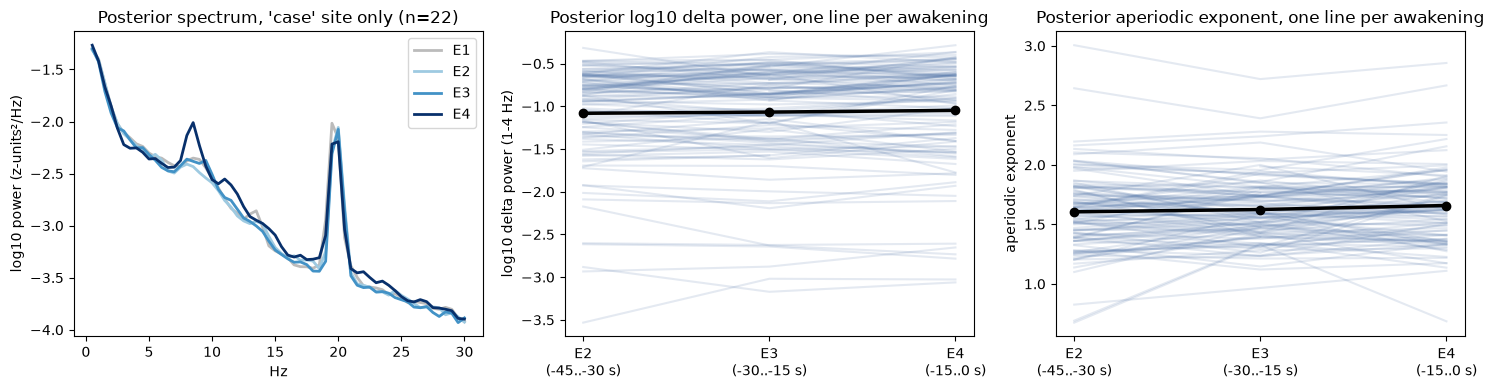

In [6]:
order = ["E1", "E2", "E3", "E4"]
cols = dict(zip(order, ["#bbbbbb", "#9ecae1", "#4292c6", "#08306b"]))
post = feat.channel.isin(fc["posterior_roi"]).values & feat.ok.values
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
# E1 exists only in the 'case' site (different hardware), so the spectrum panel uses those 22 samples
# for every epoch: a within-recording comparison rather than a site comparison.
case = (feat.site == "case").values
for e in order:
    m = post & case & (feat.epoch == e).values
    if m.any():
        ax[0].plot(f[fmask], np.log10(np.nanmean(S[m][:, fmask], 0)), color=cols[e], lw=2, label=e)
ax[0].set(xlabel="Hz", ylabel="log10 power (z-units²/Hz)",
          title=f"Posterior spectrum, 'case' site only (n={feat[case].sample_id.nunique()})"); ax[0].legend()
for a, col, lab in [(ax[1], "logpow_delta", "log10 delta power (1-4 Hz)"), (ax[2], "ap_exponent", "aperiodic exponent")]:
    d = roi[roi.epoch.isin(["E2", "E3", "E4"])].pivot_table(index="sample_id", columns="epoch", values=col)
    a.plot(range(3), d[["E2", "E3", "E4"]].T, color="#4a6fa5", alpha=.15)
    a.plot(range(3), d[["E2", "E3", "E4"]].mean(), color="k", lw=2.5, marker="o")
    a.set(xticks=range(3), xticklabels=["E2\n(-45..-30 s)", "E3\n(-30..-15 s)", "E4\n(-15..0 s)"],
          ylabel=lab, title=f"Posterior {lab.split(' (')[0]}, one line per awakening")
fig.tight_layout(); fig.savefig(figs / "features_by_epoch.pdf"); fig.savefig(figs / "features_by_epoch.png", dpi=150)
env.write_manifest(cfg, "03_features", [der / "features_long.csv", der / "features_roi.csv"],
                   notes={"n_rows": len(feat), "frac_ok": float(feat.ok.mean()),
                          "median_r2": float(np.median(ap["fit_r2"]))})